# 01 · Neural network fundamentals

**Goal:** understand how a neural network learns before we use big pretrained models on MVTec AD.
Everything here uses **Fashion-MNIST**: 70,000 small grayscale photos of clothing in 10 classes
(Xiao, Rasul and Vollgraf, Zalando Research, 2017; MIT licence). It is small enough to train a
network in a minute on a laptop, but hard enough that differences between methods show.

Sections:

1. Tensors, gradients and gradient descent, and a first look at Fashion-MNIST
2. A fully connected network and our own training loop
3. Overfitting on purpose, and three ways to stop it
4. A small convolutional network (CNN)
5. Data augmentation: when it helps and when it is wrong

The last section, *What I learned*, is written by Saheed.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST

from inspection.config import load_config, project_path
from inspection.device import get_device, set_seed
from inspection.plotting import INK, INK_MUTED, INK_SECONDARY, SERIES, apply_style

config = load_config()
SEED = config["seed"]
set_seed(SEED)
DEVICE = get_device()
DATA_DIR = project_path(config["paths"]["fashion_mnist_dir"])
RESULTS_DIR = project_path(config["paths"]["results_dir"])
apply_style()
pd.set_option("display.precision", 4)

print("PyTorch", torch.__version__, "| device:", DEVICE)

PyTorch 2.15.0 | device: mps


## 1a. Tensors

A **tensor** is PyTorch's name for a grid of numbers with any number of dimensions: one number
(0 dimensions), a list (1), a table (2), or a stack of tables (3 or more). It is the same idea as
a NumPy array, with two extras: it can live on the GPU (`mps` on this Mac), and it can record the
calculations done with it, so PyTorch can compute gradients (section 1b). Every tensor has a
**shape** (the size of each dimension), a **dtype** (the number type; networks use 32-bit
floats) and a **device**. One difference from Stage 0: NumPy and PIL store an image as
height × width × channels, but PyTorch wants **channels × height × width**, with one more
dimension in front for a batch of images.

The most important calculation inside a network layer is **matrix multiplication** (`@`). Each
row of the result is a weighted sum: for the row `[1, 2, 3]` and the weights `[0.5, -1, 2]` it
is 1·0.5 + 2·(−1) + 3·2 = 4.5.

In [2]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0, 3.0],
                       [4.0, 5.0, 6.0]])
for name, t in [("scalar", scalar), ("vector", vector), ("matrix", matrix)]:
    print(f"{name:6s}  shape={str(tuple(t.shape)):7s}  dimensions={t.ndim}  dtype={t.dtype}")

# A batch of 8 colour images of 256 x 256 pixels: the input size we chose for MVTec AD.
batch = torch.zeros(8, 3, 256, 256)
print(f"\nbatch of images: shape={tuple(batch.shape)} = {batch.numel():,} numbers")

# Stage 0 images were NumPy arrays (height, width, channels); permute reorders the dimensions.
image_hwc = np.zeros((256, 256, 3), dtype=np.uint8)
image_chw = torch.from_numpy(image_hwc).permute(2, 0, 1)
print(f"NumPy (H, W, C) {image_hwc.shape} -> PyTorch (C, H, W) {tuple(image_chw.shape)}")

weights = torch.tensor([[0.5], [-1.0], [2.0]])  # shape (3, 1)
print("\nmatrix * 2 (number by number):\n", matrix * 2)
print("matrix @ weights (one weighted sum per row):\n", matrix @ weights)

# Moving a tensor to the GPU keeps the numbers and changes where they are stored.
print("\nmatrix is now on:", matrix.to(DEVICE).device)

scalar  shape=()       dimensions=0  dtype=torch.float32
vector  shape=(3,)     dimensions=1  dtype=torch.float32
matrix  shape=(2, 3)   dimensions=2  dtype=torch.float32

batch of images: shape=(8, 3, 256, 256) = 1,572,864 numbers
NumPy (H, W, C) (256, 256, 3) -> PyTorch (C, H, W) (3, 256, 256)

matrix * 2 (number by number):
 tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
matrix @ weights (one weighted sum per row):
 tensor([[4.5000],
        [9.0000]])

matrix is now on: mps:0


## 1b. Gradients: by hand and by PyTorch

Training means changing the model's numbers, its **weights**, so that its predictions get better.
We measure "how wrong" with one number, the **loss**; here the squared error
(prediction − truth)². The **gradient** of the loss with respect to a weight says how fast the
loss changes when we nudge that weight up: a gradient of −20 means "raise this weight by 0.001
and the loss drops by about 0.02". Working this out by hand for millions of weights is
impossible, so PyTorch's **autograd** records every calculation done with tensors marked
`requires_grad=True` and then walks back through them with the chain rule. That backward walk is
**backpropagation**, and `loss.backward()` starts it.

**The smallest possible example.** A model with two weights predicts ŷ = w·x + b. Start with
w = 1, b = 0, and one training example x = 2 whose true answer is y = 7.

- Prediction: ŷ = 1·2 + 0 = 2. Loss: L = (ŷ − y)² = (2 − 7)² = **25**.
- Chain rule: dL/dw = 2(ŷ − y)·x = 2·(−5)·2 = **−20**, and dL/db = 2(ŷ − y) = 2·(−5) = **−10**.

Both gradients are negative: raising w or b lowers the loss. That makes sense, because the
prediction (2) is too low. Below, three ways to get these numbers must agree.

In [3]:
x, y = 2.0, 7.0  # one training example: input and true answer


def squared_error(w: float, b: float) -> float:
    return (w * x + b - y) ** 2


# 1) By hand, with the chain-rule formulas from the text.
w, b = 1.0, 0.0
y_hat = w * x + b
by_hand = (2 * (y_hat - y) * x, 2 * (y_hat - y))

# 2) By PyTorch. requires_grad=True tells autograd to record calculations that use w and b.
w_t = torch.tensor(1.0, requires_grad=True)
b_t = torch.tensor(0.0, requires_grad=True)
loss = (w_t * x + b_t - y) ** 2
loss.backward()  # backpropagation: fills w_t.grad and b_t.grad
by_pytorch = (w_t.grad.item(), b_t.grad.item())

# 3) By nudging: move one weight a tiny step up and down and measure how the loss changes.
#    This is the definition of a gradient, and a good check that the other two are right.
h = 1e-4
by_nudging = (
    (squared_error(w + h, b) - squared_error(w - h, b)) / (2 * h),
    (squared_error(w, b + h) - squared_error(w, b - h)) / (2 * h),
)

print(f"loss = {loss.item():.0f}")
pd.DataFrame([by_hand, by_pytorch, by_nudging], columns=["dL/dw", "dL/db"],
             index=["by hand", "by PyTorch (autograd)", "by nudging"])

loss = 25


,dL/dw,dL/db
by hand,-20.0,-10.0
by PyTorch (autograd),-20.0,-10.0
by nudging,-20.0,-10.0


## 1c. Gradient descent: learning from the gradient

The gradient points in the direction that makes the loss **bigger**, so we step the other way:
w ← w − learning rate × gradient. The **learning rate** sets the step size. Too small, and
learning is slow; too large, and each step overshoots the best value, so the loss can grow
instead of shrink. Repeating this step many times is **gradient descent**, and an **optimizer**
(here `torch.optim.SGD`) is the PyTorch object that applies the update to every weight.

With the example above and learning rate 0.01: w becomes 1 − 0.01·(−20) = 1.2 and b becomes
0 − 0.01·(−10) = 0.1. The prediction becomes 2.5 and the loss drops from 25 to 20.25.

Below, the model learns a line from 100 noisy points. The loop has five steps, and **every
training loop in this project has the same five**: forward pass, loss, clear old gradients,
backward pass, update.

In [4]:
# 100 noisy points around the line y = 3x + 2. The model does not know 3 and 2; it must learn them.
generator = torch.Generator().manual_seed(SEED)
x_line = torch.rand(100, generator=generator) * 2 - 1  # 100 values between -1 and 1
y_line = 3 * x_line + 2 + 0.3 * torch.randn(100, generator=generator)


def fit_line(lr: float, steps: int) -> tuple[float, float, list[float]]:
    """Learn w and b by gradient descent; return them and the loss after every step."""
    w = torch.zeros(1, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    optimizer = torch.optim.SGD([w, b], lr=lr)
    losses = []
    for _ in range(steps):
        y_hat = w * x_line + b                  # 1. forward pass: predict every point
        loss = ((y_hat - y_line) ** 2).mean()   # 2. loss: mean squared error
        optimizer.zero_grad()                   # 3. clear old gradients (PyTorch adds them up)
        loss.backward()                         # 4. backward pass: new gradients
        optimizer.step()                        # 5. update: w <- w - lr * gradient
        losses.append(loss.item())
    return w.item(), b.item(), losses


w_fit, b_fit, _ = fit_line(lr=0.1, steps=200)
print(f"gradient descent (lr 0.1, 200 steps): w = {w_fit:.3f}, b = {b_fit:.3f}   (true line: 3 and 2)")

# For a straight line there is also an exact formula for the best fit (least squares).
X = torch.stack([x_line, torch.ones_like(x_line)], dim=1)  # one column for w, one for b
w_best, b_best = torch.linalg.lstsq(X, y_line[:, None]).solution.flatten().tolist()
best_loss = ((w_best * x_line + b_best - y_line) ** 2).mean().item()
print(f"exact best line (least squares):      w = {w_best:.3f}, b = {b_best:.3f}, loss {best_loss:.3f}\n")

# Same data, three learning rates.
LEARNING_RATES = (0.01, 0.1, 1.05)
STEPS = 60
runs = {lr: fit_line(lr, STEPS)[2] for lr in LEARNING_RATES}
for lr, losses in runs.items():
    print(f"learning rate {lr:<5}: loss after 1 step {losses[0]:8.3f}, after {STEPS} steps {losses[-1]:12.3f}")

gradient descent (lr 0.1, 200 steps): w = 2.931, b = 2.000   (true line: 3 and 2)
exact best line (least squares):      w = 2.931, b = 2.000, loss 0.060

learning rate 0.01 : loss after 1 step    7.390, after 60 steps        1.701
learning rate 0.1  : loss after 1 step    7.390, after 60 steps        0.060
learning rate 1.05 : loss after 1 step    7.390, after 60 steps   494709.562


The learned line is not exactly y = 3x + 2, because the noise moves the points a little. But
gradient descent found the same line as the exact formula: the best any line can do on these
100 points. Its loss is not 0, because the noise is random and no line can predict it. For a
neural network there is no exact formula, which is why we train it with gradient descent.

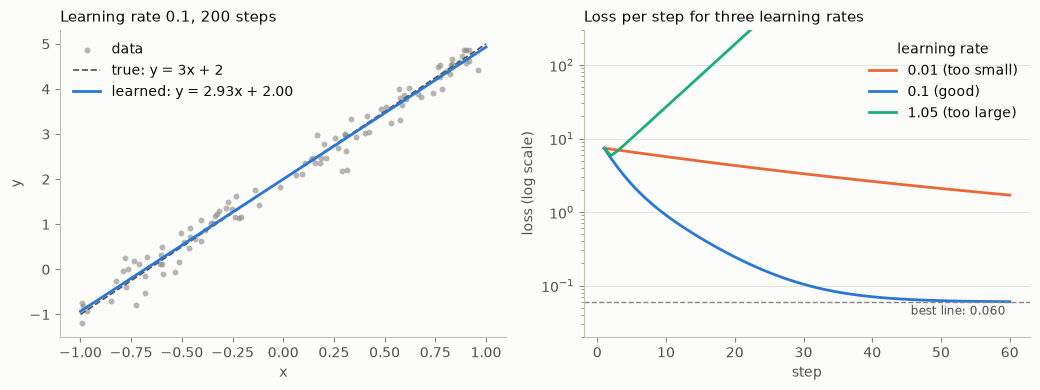

In [5]:
fig, (ax_data, ax_loss) = plt.subplots(1, 2, figsize=(10.5, 4))

grid_x = torch.linspace(-1, 1, 2)
ax_data.scatter(x_line, y_line, s=18, color=INK_MUTED, alpha=0.6, linewidths=0, label="data")
ax_data.plot(grid_x, 3 * grid_x + 2, color=INK_SECONDARY, lw=1.2, ls="--", label="true: y = 3x + 2")
ax_data.plot(grid_x, w_fit * grid_x + b_fit, color=SERIES[0], lw=2,
             label=f"learned: y = {w_fit:.2f}x + {b_fit:.2f}")
ax_data.set_xlabel("x")
ax_data.set_ylabel("y")
ax_data.set_title("Learning rate 0.1, 200 steps", loc="left")
ax_data.legend(loc="upper left")

# Colour follows the run: learning rate 0.1 is blue here and in the left panel; any other
# learning rate takes the next colour in order.
notes = {0.01: " (too small)", 0.1: " (good)", 1.05: " (too large)"}
other_colours = iter(SERIES[1:])
for lr, losses in runs.items():
    colour = SERIES[0] if lr == 0.1 else next(other_colours)
    ax_loss.plot(range(1, len(losses) + 1), losses, color=colour, lw=2,
                 label=f"{lr}{notes.get(lr, '')}")
ax_loss.axhline(best_loss, color=INK_MUTED, lw=1, ls="--")
ax_loss.text(STEPS, best_loss * 0.92, f"best line: {best_loss:.3f} ", ha="right", va="top",
             fontsize=8.5, color=INK_SECONDARY)
ax_loss.set_yscale("log")
ax_loss.set_ylim(0.02, 300)
ax_loss.set_xlabel("step")
ax_loss.set_ylabel("loss (log scale)")
ax_loss.set_title("Loss per step for three learning rates", loc="left")
ax_loss.grid(axis="y")
ax_loss.set_axisbelow(True)
ax_loss.legend(title="learning rate", loc="upper right")
fig.tight_layout()
plt.show()

## 1d. A first look at Fashion-MNIST

Fashion-MNIST has 60,000 training and 10,000 test images, each 28 × 28 pixels, grayscale, with
one of 10 labels. We take 10,000 of the 60,000 training images away as a **validation set**. The
model never trains on it; we use it to make choices, such as when to stop training. The test set
is used once, at the very end. This is the same rule as for MVTec AD: whatever we use to make
choices cannot also tell us honestly how good the final model is.

The split is random but fixed by the seed, so every run uses the same 50,000 / 10,000 images.

In [6]:
train_full = FashionMNIST(DATA_DIR, train=True, download=True)  # downloads ~30 MB the first time
test_set = FashionMNIST(DATA_DIR, train=False, download=True)
CLASSES = train_full.classes

# Fixed random split of the 60,000 training images: 50,000 train, 10,000 validation.
order = torch.randperm(len(train_full), generator=torch.Generator().manual_seed(SEED))
val_idx, train_idx = order[:10_000], order[10_000:]

labels = train_full.targets
split_counts = pd.DataFrame({
    "train": torch.bincount(labels[train_idx], minlength=10).numpy(),
    "validation": torch.bincount(labels[val_idx], minlength=10).numpy(),
    "test": torch.bincount(test_set.targets, minlength=10).numpy(),
}, index=pd.Index(CLASSES, name="class"))
split_counts.loc["total"] = split_counts.sum()
split_counts.to_csv(RESULTS_DIR / "stage1_fashion_split.csv")
split_counts

,train,validation,test
class,,,
T-shirt/top,5020,980,1000
Trouser,5021,979,1000
Pullover,4939,1061,1000
Dress,5026,974,1000
Coat,4954,1046,1000
Sandal,4945,1055,1000
Shirt,5016,984,1000
Sneaker,5007,993,1000
Bag,5043,957,1000


Every class has about the same number of images in every split, so a model that always guesses
one class would be right only 10% of the time. That is the floor any model must beat.

An image is a 28 × 28 grid of numbers from 0 (black background) to 255 (white). Below, the
pixel values in the middle of the first training image, and the image itself.

shape (28, 28), dtype torch.uint8, values 0 to 255, label 9 = Ankle boot
rows 10-15, columns 10-15:
tensor([[  0,   0,   0, 193, 228, 218],
        [  3,   0,  12, 219, 220, 212],
        [  6,   0,  99, 244, 222, 220],
        [  0,   0,  55, 236, 228, 230],
        [  0,   0, 237, 226, 217, 223],
        [145, 204, 228, 207, 213, 221]], dtype=torch.uint8)


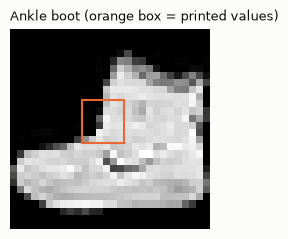

In [7]:
image, label = train_full.data[0], train_full.targets[0].item()
print(f"shape {tuple(image.shape)}, dtype {image.dtype}, values {image.min().item()} to {image.max().item()}, "
      f"label {label} = {CLASSES[label]}")
print("rows 10-15, columns 10-15:")
print(image[10:16, 10:16])

fig, ax = plt.subplots(figsize=(2.6, 2.6))
ax.imshow(image, cmap="gray", vmin=0, vmax=255)
ax.add_patch(plt.Rectangle((9.5, 9.5), 6, 6, fill=False, ec=SERIES[1], lw=1.5))
ax.set_title(f"{CLASSES[label]} (orange box = printed values)", fontsize=9, loc="left")
ax.axis("off")
plt.show()

Ten random training images per class. Some classes are easy to tell apart (trouser, bag), others
look alike even to us (T-shirt/top, shirt, pullover, coat). Expect the model's mistakes there.

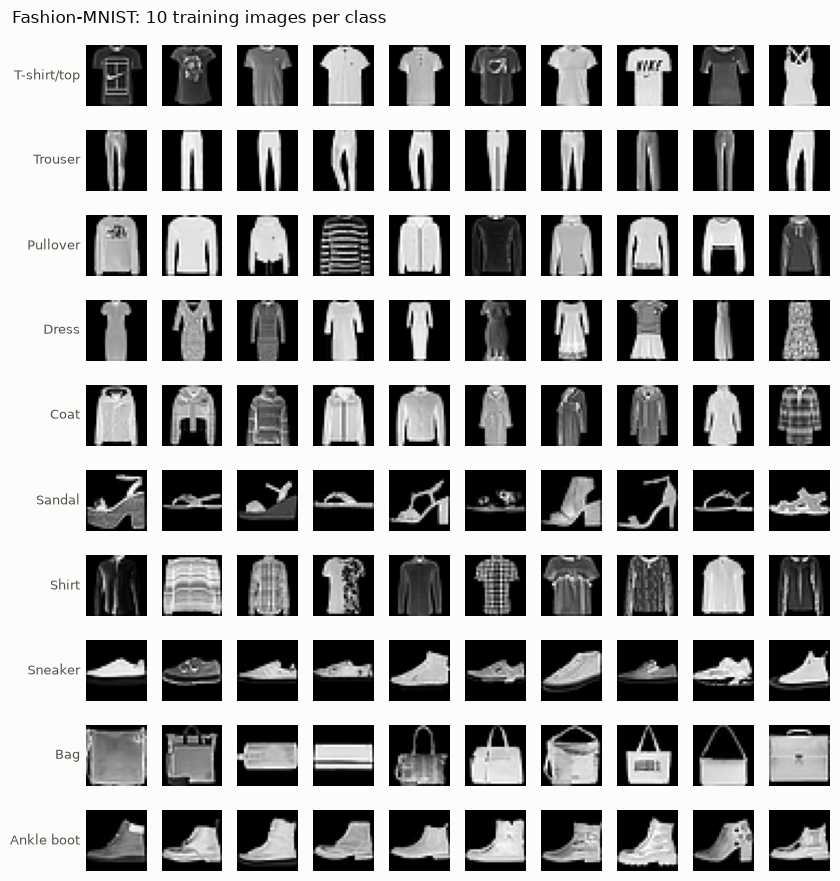

In [8]:
PER_CLASS = 10
rng = np.random.default_rng(SEED)
train_labels = labels[train_idx].numpy()

fig, axes = plt.subplots(10, PER_CLASS, figsize=(PER_CLASS * 0.85, 10 * 0.9))
for c, class_name in enumerate(CLASSES):
    picks = rng.choice(train_idx.numpy()[train_labels == c], PER_CLASS, replace=False)
    for ax, i in zip(axes[c], picks):
        ax.imshow(train_full.data[i], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[c, 0].set_ylabel(class_name, rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Fashion-MNIST: 10 training images per class", x=0.02, ha="left")
fig.tight_layout()
plt.show()

## 2. A fully connected network

Now a real classifier: the network sees a 28 × 28 image and must say which of the 10 classes it
is. We build it in four steps: prepare the data, define the model, choose the loss, train it with
our own loop. Then we read the training curves and look at the mistakes.

### 2a. Preparing the data: scaling and mini-batches

Networks learn best when the input numbers are small and centred around 0. So we divide the
pixels by 255 (now 0 to 1), then subtract the mean and divide by the standard deviation. We
compute that mean and standard deviation on the **training images only**: if the validation
images helped set the scaling, a little information about them would leak into training.

A gradient computed on all 50,000 images is exact but slow, and gives only one update per pass
through the data. Instead each update uses a **mini-batch** of 128 random images: the gradient is
a bit noisy, but we get 391 updates per pass instead of 1. One pass through all training images
is an **epoch**. A PyTorch **DataLoader** cuts the data into mini-batches and shuffles it again
every epoch, so the batches are different each time.

In [9]:
# Mean and standard deviation of the training pixels only (0-1 scale).
train_pixels = train_full.data[train_idx].float() / 255
PIXEL_MEAN, PIXEL_STD = train_pixels.mean().item(), train_pixels.std().item()


def to_model_input(images: torch.Tensor) -> torch.Tensor:
    """uint8 images (N, 28, 28) -> scaled floats (N, 1, 28, 28). The 1 is the channel: grayscale."""
    x = images.float() / 255
    return ((x - PIXEL_MEAN) / PIXEL_STD).unsqueeze(1)


X_train, y_train = to_model_input(train_full.data[train_idx]), train_full.targets[train_idx]
X_val, y_val = to_model_input(train_full.data[val_idx]), train_full.targets[val_idx]
print(f"training pixels (0-1 scale): mean {PIXEL_MEAN:.4f}, std {PIXEL_STD:.4f}")
print(f"after scaling:               mean {X_train.mean():.4f}, std {X_train.std():.4f}")

BATCH_SIZE = 128


def make_loader(x: torch.Tensor, y: torch.Tensor, shuffle: bool) -> DataLoader:
    """Mini-batches of (images, labels). A seeded generator makes the shuffling repeatable."""
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(TensorDataset(x, y), batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)


val_loader = make_loader(X_val, y_val, shuffle=False)
example_images, example_labels = next(iter(make_loader(X_train, y_train, shuffle=True)))
print(f"\none mini-batch: images {tuple(example_images.shape)}, labels {tuple(example_labels.shape)}")
print(f"mini-batches per epoch: {len(make_loader(X_train, y_train, shuffle=True))}")

training pixels (0-1 scale): mean 0.2859, std 0.3529
after scaling:               mean -0.0000, std 1.0000

one mini-batch: images (128, 1, 28, 28), labels (128,)
mini-batches per epoch: 391


### 2b. The model: layers and activations

A **linear layer** (`nn.Linear`) is the matrix multiplication from 1a plus a bias: every output
is a weighted sum of all inputs, and training learns the weights. It is called *fully connected*
because every input is connected to every output. Stacking only linear layers would be pointless:
a linear function of a linear function is still linear, so ten such layers can do no more than
one. An **activation function** between the layers bends the result. We use **ReLU**, which keeps
positive numbers and turns negative ones into 0: ReLU(−2) = 0, ReLU(3) = 3.

In PyTorch a model is a class that inherits from `nn.Module`: `__init__` creates the layers and
`forward` says how data flows through them. Ours flattens the 28 × 28 image into 784 numbers,
passes them through two hidden layers of 256 units, and ends with 10 numbers, one score per
class. These raw scores are called **logits**.

In [10]:
class FullyConnected(nn.Module):
    """Image -> 784 numbers -> 256 -> 256 -> 10 class scores (logits)."""

    def __init__(self, hidden: int = 256) -> None:
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),                # (N, 1, 28, 28) -> (N, 784): the image as one long row
            nn.Linear(28 * 28, hidden),  # hidden layer 1
            nn.ReLU(),
            nn.Linear(hidden, hidden),   # hidden layer 2
            nn.ReLU(),
            nn.Linear(hidden, 10),       # output layer: one score per class
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


def parameter_table(model: nn.Module) -> pd.DataFrame:
    """One row per weight tensor: its shape and how many numbers training must learn."""
    rows = [{"parameter": name, "shape": tuple(p.shape), "count": p.numel()}
            for name, p in model.named_parameters()]
    table = pd.DataFrame(rows).set_index("parameter")
    table.loc["total"] = ["", table["count"].sum()]
    return table


set_seed(SEED)
print(FullyConnected())
parameter_table(FullyConnected())

FullyConnected(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)


,shape,count
parameter,,
layers.1.weight,"(256, 784)",200704
layers.1.bias,"(256,)",256
layers.3.weight,"(256, 256)",65536
layers.3.bias,"(256,)",256
layers.5.weight,"(10, 256)",2560
layers.5.bias,"(10,)",10
total,,269322


The weights of the first layer have shape (256, 784): one row of 784 weights for each of the 256
units. With the 256 biases that is 784 × 256 + 256 = **200,960** numbers, three quarters of the
whole model. Every pixel is connected to every unit, which is why fully connected networks get
big quickly on larger images.

An untrained model already gives an answer; it is just random. Its 10 logits for one image:

In [11]:
set_seed(SEED)
untrained = FullyConnected()
logits = untrained(example_images)  # forward pass on one mini-batch of 128 images
print("logits:", tuple(logits.shape), "= 128 images x 10 class scores")
print("first image:", logits[0].detach().numpy().round(3))

logits: (128, 10) = 128 images x 10 class scores
first image: [-0.033  0.106 -0.034 -0.213  0.058 -0.137  0.103 -0.022  0.052 -0.066]


### 2c. The loss: cross-entropy

The 10 logits can be any numbers. **Softmax** turns them into probabilities: it makes every
number positive (eˣ) and divides by the sum, so the 10 values add up to 1. **Cross-entropy
loss** then looks only at the probability the model gave to the *true* class and takes −log of
it. Probability 0.9 gives a loss of 0.11, 0.5 gives 0.69, 0.1 gives 2.30, and a confident wrong
answer (0.01) gives 4.61, so confident mistakes are punished hardest.

A useful check: an untrained model gives every class about the same probability, 1/10, so its
loss should start near −log(0.1) = **2.30**. If it starts far from that, something is wired
wrong. `nn.CrossEntropyLoss` takes the logits directly and does the softmax itself.

In [12]:
loss_fn = nn.CrossEntropyLoss()

print("probability of the true class -> loss")
for p in (0.9, 0.5, 0.1, 0.01):
    print(f"  {p:<5} -> -log({p}) = {-np.log(p):.2f}")

probabilities = torch.softmax(logits, dim=1)
print("\nuntrained model, first image, probabilities:", probabilities[0].detach().numpy().round(3))
print(f"sum of the 10 probabilities: {probabilities[0].sum().item():.3f}")

# The same loss by hand (softmax, pick the true class, -log, average) and by PyTorch.
by_hand = -torch.log(probabilities[torch.arange(len(example_labels)), example_labels]).mean()
print(f"\nloss on this mini-batch: by hand {by_hand.item():.4f}, "
      f"by nn.CrossEntropyLoss {loss_fn(logits, example_labels).item():.4f}, "
      f"expected about {-np.log(0.1):.4f}")

probability of the true class -> loss
  0.9   -> -log(0.9) = 0.11
  0.5   -> -log(0.5) = 0.69
  0.1   -> -log(0.1) = 2.30
  0.01  -> -log(0.01) = 4.61

untrained model, first image, probabilities: [0.098 0.113 0.098 0.082 0.107 0.088 0.112 0.099 0.107 0.095]
sum of the 10 probabilities: 1.000

loss on this mini-batch: by hand 2.3113, by nn.CrossEntropyLoss 2.3113, expected about 2.3026


### 2d. The training loop

The loop is the same five steps as in 1c, now repeated for every mini-batch of every epoch. After
each epoch we measure loss and accuracy on the validation set, without training on it.
`torch.no_grad()` tells PyTorch not to record calculations there (nothing is learned, and it
saves memory). `model.eval()` switches some layers to their test behaviour; our model has none
yet, but dropout in section 3 does. Instead of plain SGD we now use **Adam**, an optimizer that
adapts the step size of each weight to the history of its gradients. Its standard learning rate,
0.001, works for most networks without tuning, and we use it for the rest of the project.

In [13]:
def train_one_epoch(model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer) -> float:
    """One pass over the training data. Returns the average loss over the epoch."""
    model.train()
    total_loss, n = 0.0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)           # 1. forward pass
        loss = loss_fn(logits, labels)   # 2. loss
        optimizer.zero_grad()            # 3. clear old gradients
        loss.backward()                  # 4. backward pass
        optimizer.step()                 # 5. update the weights
        total_loss += loss.item() * len(labels)
        n += len(labels)
    return total_loss / n


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader) -> tuple[torch.Tensor, torch.Tensor]:
    """Logits and true labels for a whole dataset, on the CPU."""
    model.eval()
    all_logits, all_labels = [], []
    for images, labels in loader:
        all_logits.append(model(images.to(DEVICE)).cpu())
        all_labels.append(labels)
    return torch.cat(all_logits), torch.cat(all_labels)


def evaluate(model: nn.Module, loader: DataLoader) -> tuple[float, float]:
    """Average loss and accuracy on a dataset, without training."""
    logits, labels = predict(model, loader)
    accuracy = (logits.argmax(dim=1) == labels).float().mean().item()
    return loss_fn(logits, labels).item(), accuracy


def fit(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader, epochs: int,
        lr: float = 1e-3) -> pd.DataFrame:
    """Train with Adam; return one row per epoch.

    The training loss is averaged over the epoch while the weights were still changing, so it is
    a little higher than the loss of the model at the end of the epoch.
    """
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    rows = []
    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        train_loss = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_accuracy = evaluate(model, val_loader)
        rows.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                     "val_accuracy": val_accuracy, "seconds": time.perf_counter() - start})
    return pd.DataFrame(rows).set_index("epoch")

In [14]:
EPOCHS = 20
set_seed(SEED)
fc_model = FullyConnected()
start = time.perf_counter()
fc_history = fit(fc_model, make_loader(X_train, y_train, shuffle=True), val_loader, EPOCHS)
print(f"training time: {time.perf_counter() - start:.1f} s for {EPOCHS} epochs on {DEVICE}")
fc_history.to_csv(RESULTS_DIR / "stage1_fc_history.csv")
fc_history.round(4)

training time: 11.9 s for 20 epochs on mps


,train_loss,val_loss,val_accuracy,seconds
epoch,,,,
1,0.4927,0.4039,0.8498,1.1882
2,0.3573,0.3449,0.8712,0.9586
3,0.3151,0.3244,0.8786,0.5545
4,0.2884,0.3478,0.8705,0.5266
5,0.2684,0.3204,0.8850,0.5368
6,0.2530,0.3172,0.8884,0.5229
7,0.2357,0.3274,0.8862,0.5208
8,0.2224,0.3227,0.8864,0.5200
9,0.2091,0.3649,0.8825,0.5344


### 2e. Reading the training curves

The most useful plot in deep learning: training loss and validation loss after every epoch. While
both fall, the model is learning things that hold for new images too. When the training loss
keeps falling but the validation loss stops falling or rises, the model has started to learn
details of its own training images that do not hold for new ones.

lowest validation loss: epoch 6, loss 0.3172, accuracy 88.84%
last epoch (20):         loss 0.3967, accuracy 89.53%
training loss fell from 0.4927 to 0.1128


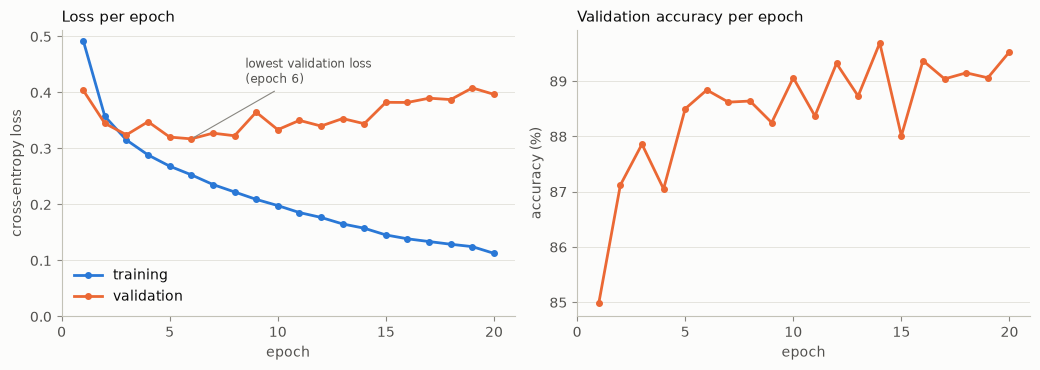

In [15]:
best_epoch = int(fc_history.val_loss.idxmin())
best = fc_history.loc[best_epoch]
last = fc_history.iloc[-1]
print(f"lowest validation loss: epoch {best_epoch}, loss {best.val_loss:.4f}, accuracy {best.val_accuracy:.2%}")
print(f"last epoch ({EPOCHS}):         loss {last.val_loss:.4f}, accuracy {last.val_accuracy:.2%}")
print(f"training loss fell from {fc_history.train_loss.iloc[0]:.4f} to {last.train_loss:.4f}")

TRAIN_COLOUR, VAL_COLOUR = SERIES[0], SERIES[1]  # training = blue, validation = orange, in every plot
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax_loss.plot(fc_history.index, fc_history.train_loss, color=TRAIN_COLOUR, lw=2, marker="o", ms=4,
             label="training")
ax_loss.plot(fc_history.index, fc_history.val_loss, color=VAL_COLOUR, lw=2, marker="o", ms=4,
             label="validation")
ax_loss.annotate(f"lowest validation loss\n(epoch {best_epoch})", xy=(best_epoch, best.val_loss),
                 xytext=(best_epoch + 2.5, best.val_loss + 0.1), fontsize=8.5, color=INK_SECONDARY,
                 arrowprops={"arrowstyle": "-", "color": INK_MUTED, "lw": 0.8})
ax_loss.set_xlabel("epoch")
ax_loss.set_ylabel("cross-entropy loss")
ax_loss.set_title("Loss per epoch", loc="left")
ax_loss.set_ylim(0, None)
ax_loss.grid(axis="y")
ax_loss.set_axisbelow(True)
ax_loss.legend(loc="lower left")

ax_acc.plot(fc_history.index, 100 * fc_history.val_accuracy, color=VAL_COLOUR, lw=2, marker="o", ms=4)
ax_acc.set_xlabel("epoch")
ax_acc.set_ylabel("accuracy (%)")
ax_acc.set_title("Validation accuracy per epoch", loc="left")
ax_acc.grid(axis="y")
ax_acc.set_axisbelow(True)
for ax in (ax_loss, ax_acc):
    ax.set_xticks(range(0, EPOCHS + 1, 5))
fig.tight_layout()
plt.show()

**What the curves show.** The training loss falls in every epoch, but the validation loss is
lowest after about 6 epochs and then rises again. From there on the model is learning details of
its 50,000 training images that do not help on new images: it has started to **overfit**.

Validation accuracy hardly suffers (it stays between 88% and 90%), so what goes wrong? The model
becomes *more confident*, also in its wrong answers, and cross-entropy punishes confident
mistakes hard (2c). The mistakes in 2f show this. Section 3 makes overfitting much stronger on
purpose and shows three ways to stop it.

The small ups and downs from one epoch to the next are noise: every epoch sees the mini-batches
in a different order. Do not read meaning into a single epoch.

### 2f. Looking at the mistakes

Accuracy is one number. A **confusion matrix** shows *which* classes get mixed up: each row is
the true class, each column the class the model predicted, so the diagonal holds the correct
answers. Below, the diagonal is grey and only the mistakes are coloured, darker for more.

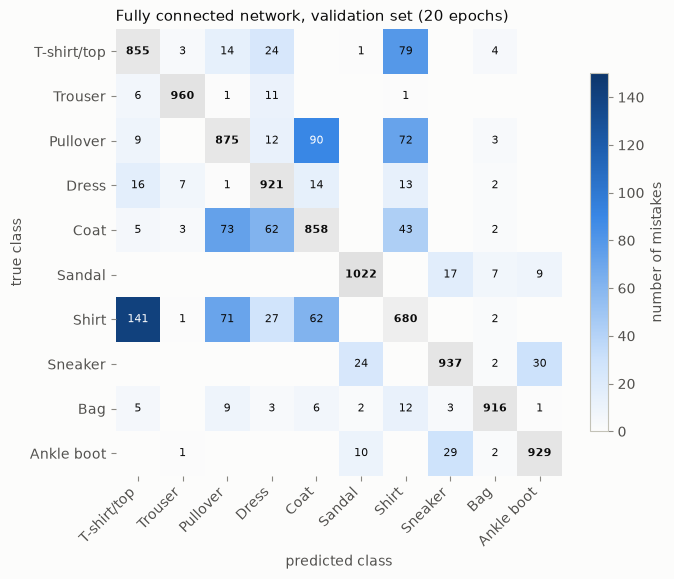

accuracy per class, worst first:
Shirt          69.1
Coat           82.0
Pullover       82.5
T-shirt/top    87.2
Sneaker        94.4
Dress          94.6
Ankle boot     95.7
Bag            95.7
Sandal         96.9
Trouser        98.1


In [16]:
val_logits, val_labels = predict(fc_model, val_loader)
val_predictions = val_logits.argmax(dim=1)


def confusion_matrix(labels: torch.Tensor, predictions: torch.Tensor) -> np.ndarray:
    """10 x 10 counts: row = true class, column = predicted class."""
    return torch.bincount(labels * 10 + predictions, minlength=100).reshape(10, 10).numpy()


MISTAKE_CMAP = LinearSegmentedColormap.from_list(
    "mistakes", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])


def plot_confusion(cm: np.ndarray, title: str) -> None:
    """Mistakes coloured by count (same blue scale for every model); correct answers in grey."""
    mistakes = np.ma.masked_where(np.eye(10, dtype=bool), cm)
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    image = ax.imshow(mistakes, cmap=MISTAKE_CMAP, vmin=0, vmax=max(150, mistakes.max()))
    ax.imshow(np.ma.masked_where(~np.eye(10, dtype=bool), cm), cmap="Greys", vmin=0, vmax=5000)
    for i in range(10):
        for j in range(10):
            if cm[i, j] == 0:
                continue
            dark = i != j and cm[i, j] > 0.55 * max(150, mistakes.max())
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="#ffffff" if dark else INK, fontweight="bold" if i == j else None)
    ax.set_xticks(range(10), CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(10), CLASSES)
    ax.set_xlabel("predicted class")
    ax.set_ylabel("true class")
    ax.set_title(title, loc="left")
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(image, ax=ax, shrink=0.75, label="number of mistakes")
    plt.show()


fc_confusion = confusion_matrix(val_labels, val_predictions)
pd.DataFrame(fc_confusion, index=CLASSES, columns=CLASSES).to_csv(RESULTS_DIR / "stage1_fc_confusion.csv")
plot_confusion(fc_confusion, f"Fully connected network, validation set ({EPOCHS} epochs)")

per_class = pd.Series(np.diag(fc_confusion) / fc_confusion.sum(axis=1), index=CLASSES, name="accuracy")
print("accuracy per class, worst first:")
print((100 * per_class.sort_values()).round(1).to_string())

The mistakes the model is *most sure about*: wrong answers with the highest predicted
probability. Looking at them tells you whether the model is stupid or the task is hard (or the
label is wrong).

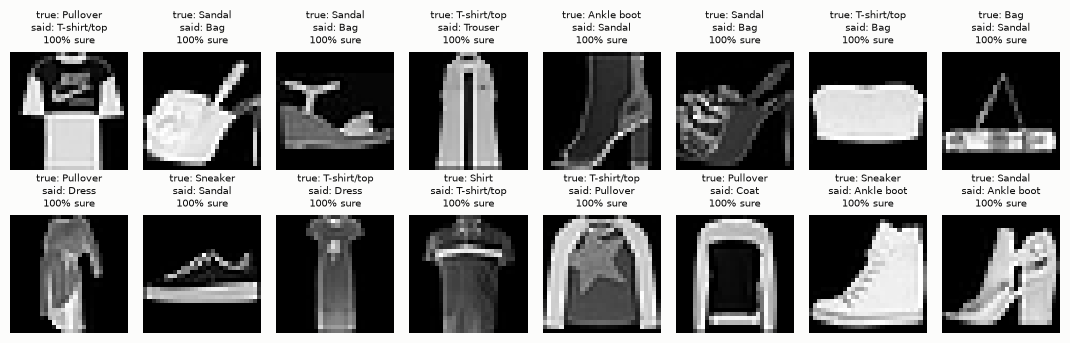

In [17]:
def show_confident_mistakes(logits: torch.Tensor, labels: torch.Tensor, n: int = 16) -> None:
    """Grid of the n wrong predictions with the highest probability for the wrong class."""
    probabilities = torch.softmax(logits, dim=1)
    confidence, predictions = probabilities.max(dim=1)
    wrong = torch.nonzero(predictions != labels).flatten()
    worst = wrong[confidence[wrong].argsort(descending=True)[:n]]
    fig, axes = plt.subplots(2, n // 2, figsize=(n // 2 * 1.35, 3.6))
    for ax, i in zip(axes.flat, worst.tolist()):
        ax.imshow(train_full.data[val_idx[i]], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"true: {CLASSES[labels[i]]}\nsaid: {CLASSES[predictions[i]]}\n"
                     f"{confidence[i]:.0%} sure", fontsize=7.5)
        ax.axis("off")
    fig.tight_layout()
    plt.show()


show_confident_mistakes(val_logits, val_labels)

**What the mistakes show.**

- **Mix-ups happen between classes with the same shape.** Most mistakes are among the tops
  (shirt, T-shirt/top, pullover, coat) and among the shoes (sneaker, sandal, ankle boot).
  Shirt is by far the hardest class: only 69% of shirts are recognised, and 141 of them are
  called T-shirt/top. Trousers and bags are almost never confused with anything.
- **The model is sure of itself even when it is wrong.** Its most confident mistakes get about
  100% probability. This is the overconfidence that makes the validation loss rise in 2e.
- **Some labels are doubtful.** A few of these images look more like the predicted class than
  their label (the first one, labelled Pullover, looks like a T-shirt). No model can get those
  right, so 100% accuracy is not a realistic goal.

For MVTec AD we will use the same habit: look at the most confident mistakes to tell whether a
missed defect is the model's fault or a defect that is barely visible.

## What I learned

*(Saheed writes this section.)*

- 

I at a point changed the Learning rate from 0.01, 01., 1.05 to 0.01, 1.05, 1.0 and the green line had disappeared from the curve